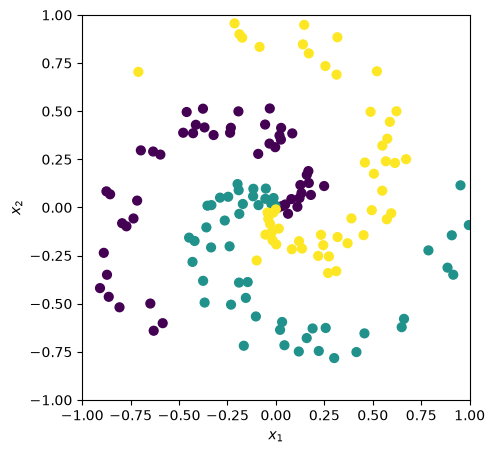

In [28]:
import matplotlib.pyplot as plt
import numpy as np

N = 50 # number of points per branch
K = 3  # number of branches

N_train = N*K # total number of points in the training set
x_train = np.zeros((N_train,2)) # initialize matrix containing the 2-dimensional datapoints
y_train = np.zeros(N_train, dtype='uint8') # initialize labels, positive integer

mag_noise = 0.3  # controls how much noise gets added to the data
dTheta    = 4    # difference in theta in each branch

### Data generation: ###
for j in range(K):
  ix = range(N*j,N*(j+1))
  r  = np.linspace(0.01,1,N) # radius
  th = np.linspace(j*(2*np.pi)/K,j*(2*np.pi)/K + dTheta,N) + np.random.randn(N)*mag_noise # distribute points about theta curve
  x_train[ix] = np.c_[r*np.cos(th), r*np.sin(th)]
  y_train[ix] = j

### Plot the data set: ###
fig = plt.figure(1, figsize=(5,5))
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=40)#, cmap=plt.cm.Spectral)
plt.xlim([-1,1])
plt.ylim([-1,1])
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.savefig('spiral_data.pdf', bbox_inches="tight")
plt.show()


In [29]:
%matplotlib inline
from IPython import display

import time
import torch

class FeedforwardNN(torch.nn.Module):
    def __init__(self, input_size, output_size, mid_size_array, activation_flag):
        super(FeedforwardNN, self).__init__()

        self.input_size = input_size
        self.output_size = output_size
        self.mid_size_array = mid_size_array # Hidden layer sizes

        # Use ModuleList to hold a dynamic number of layers
        self.hidden_layers = torch.nn.ModuleList()

        # 1. First layer: Input -> First hidden size
        self.hidden_layers.append(torch.nn.Linear(self.input_size, self.mid_size_array[0]))

        # 2. Middle layers: Hidden(i) -> Hidden(i+1)
        for i in range(len(self.mid_size_array) - 1):
            self.hidden_layers.append(torch.nn.Linear(self.mid_size_array[i], self.mid_size_array[i+1]))

        # 3. Final layer: Last hidden size -> Output
        self.output_layer = torch.nn.Linear(self.mid_size_array[-1], self.output_size)

        # activation, determined by flag
        if activation_flag == 'relu':
            self.activation = torch.nn.ReLU()
        elif activation_flag == 'sigmoid':
            self.activation = torch.nn.Sigmoid()
        elif activation_flag == 'softmax':
            self.activation = torch.nn.Softmax(dim=1) # dim=1 is standard for batched inputs
        else:
            raise ValueError(f"Invalid activation_flag '{activation_flag}'. Choose 'relu', 'sigmoid', or 'softmax'.")

    def forward(self, x):
        # Iterate over all the hidden layers
        for layer in self.hidden_layers:
            # Pass data through the linear layer, then the activation function
            x = layer(x)
            x = self.activation(x)

        # Pass through the final output layer (usually no activation before loss computation)
        out = self.output_layer(x)

        return out


In [30]:
def setup_model_and_data(x_train, y_train, K, mid_size_array, learning_rate=1.0, N_epochs=10000, activation_flag='sigmoid'): #use sigmoid by default

    # Dynamically grab input_size from data (e.g., 2 if x_train has 2 columns)
    # Alternatively, you can hardcode input_size = 2 if you prefer
    input_size = x_train.shape[1] if hasattr(x_train, 'shape') else print('x_train has no shape')
    output_size = K

    #Initialize the model
    model = FeedforwardNN(input_size, output_size, mid_size_array, activation_flag)

    #Store the input data as a PyTorch tensor
    x_train_tensor = torch.tensor(x_train, dtype=torch.float)

    #One hot encoding for labels
    y_onehot = np.zeros((y_train.size, K))
    y_onehot[np.arange(y_train.size), y_train] = 1
    y_onehot = torch.tensor(y_onehot, dtype=torch.float)

    #Setup Optimizer and Cost Function
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    cost_func = torch.nn.MSELoss()

    return model, x_train_tensor, y_onehot, optimizer, cost_func

In [31]:
############ Function for plotting: ############
def updatePlot(model,epoch_list,cost_training,acc_training):

    ### Generate coordinates covering the whole plane: ###
    padding = 0.1
    spacing = 0.02
    x1_min, x1_max = x_train[:, 0].min() - padding, x_train[:, 0].max() + padding
    x2_min, x2_max = x_train[:, 1].min() - padding, x_train[:, 1].max() + padding
    x1_grid, x2_grid = np.meshgrid(np.arange(x1_min, x1_max, spacing),
                         np.arange(x2_min, x2_max, spacing))

    torch_input = torch.tensor(np.c_[x1_grid.ravel(), x2_grid.ravel()], dtype = torch.float)
    NN_output = model(torch_input)
    predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)

    ### Plot the classifier: ###
    plt.subplot(121)
    plt.contourf(x1_grid, x2_grid, predicted_class.reshape(x1_grid.shape), K, alpha=0.8)
    plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=40)
    plt.xlim(x1_grid.min(), x1_grid.max())
    plt.ylim(x2_grid.min(), x2_grid.max())
    plt.xlabel(r'$x_1$')
    plt.ylabel(r'$x_2$')

    ### Plot the cost function during training: ###
    plt.subplot(222)
    plt.plot(epoch_list,cost_training,'o-')
    plt.xlabel('Epoch')
    plt.ylabel('Training cost')

    ### Plot the training accuracy: ###
    plt.subplot(224)
    plt.plot(epoch_list,acc_training,'o-')
    plt.xlabel('Epoch')
    plt.ylabel('Training accuracy')
############ End of plotting function ############


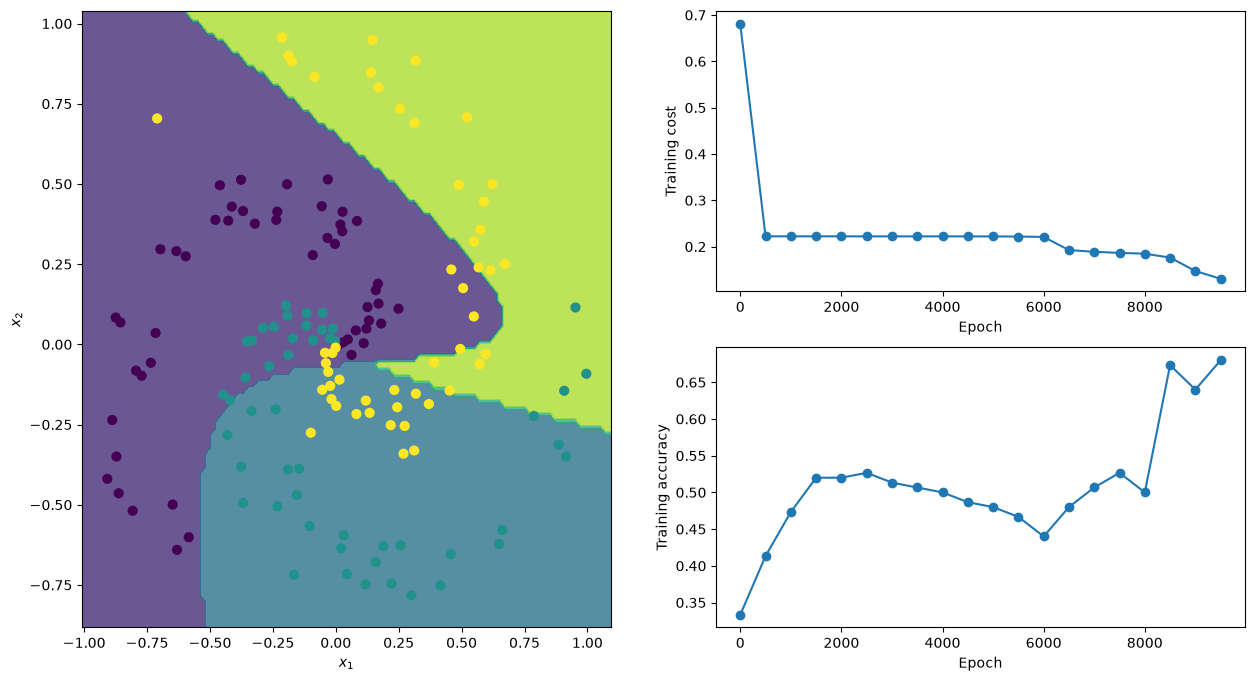

[SOFTMAX] Iteration 9500:
  Training cost 0.130601
  Training accuracy 0.680000

Saved spiral_results_softmax.pdf
Final SOFTMAX Training cost 0.109899
Final SOFTMAX Training accuracy 0.680000

--------------------------------------------------


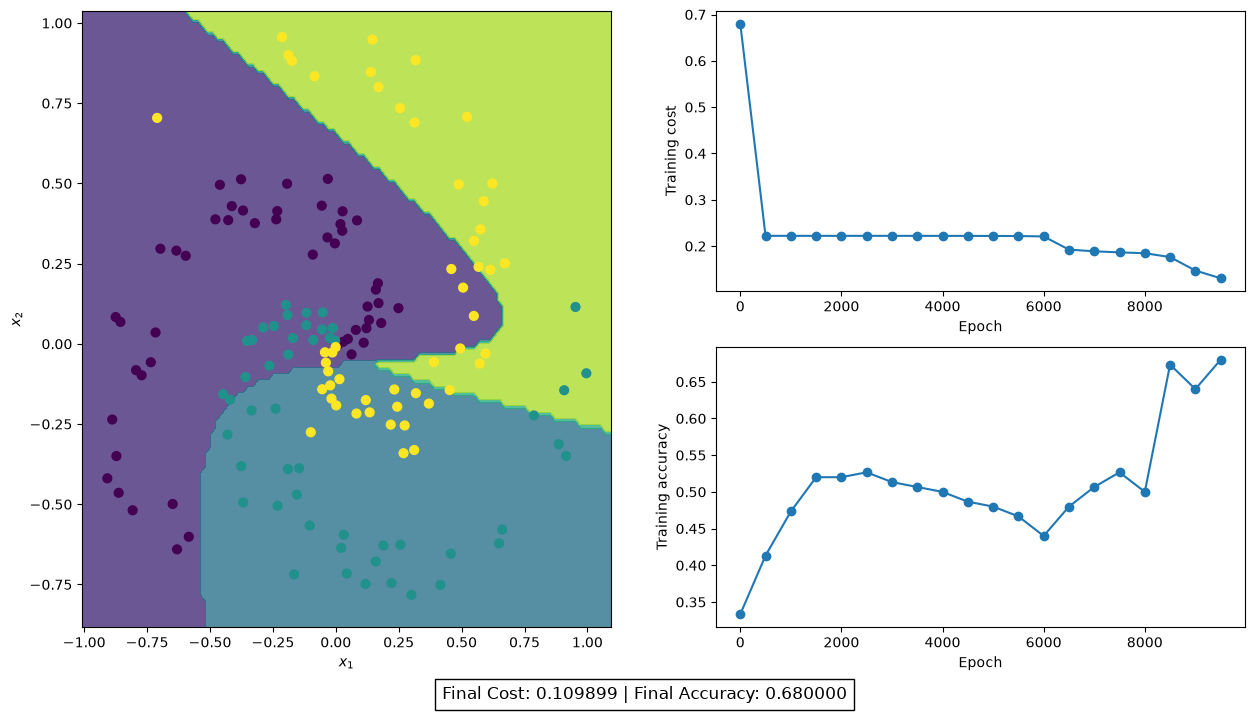

In [32]:
N_epochs = 10000

# Loop through different activation functions
for act in ('relu', 'sigmoid', 'softmax'):
    mid_size_array = [10, 8, 6]

    #get model variables
    model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(
        x_train, y_train, K, mid_size_array, 1.0, N_epochs, act
    )

    epoch_list    = []
    cost_training = []
    acc_training  = []

    ### Train for several epochs: ###
    for epoch in range(N_epochs):

        optimizer.zero_grad()
        NN_output = model(x_train_tensor) # Use the tensor returned by your setup function
        cost = cost_func(NN_output, y_onehot)
        cost.backward()
        optimizer.step()

        ### Update the plot and print results every 500 epochs: ###
        if epoch % 500 == 0:
            predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
            accuracy = np.mean(predicted_class == y_train)

            epoch_list.append(epoch)
            cost_training.append(cost.detach().numpy())
            acc_training.append(accuracy)

            ### Update the plot of the resulting classifier: ###
            fig = plt.figure(2, figsize=(15,8))
            fig.subplots_adjust(hspace=.3, wspace=.3)
            plt.clf()

            updatePlot(model,epoch_list,cost_training,acc_training)

            display.display(plt.gcf())
            print(f"[{act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

            #Stop clearing the output on the very last step so the final plot stays visible
            if epoch < N_epochs - 500:
                display.clear_output(wait=True)
            # time.sleep(0.1)

    #
    metrics_text = f"Final Cost: {cost:.6f} | Final Accuracy: {accuracy:.6f}"
    plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12,
                bbox={"facecolor":"white", "pad":5})

    #Dynamically name the file based on the activation function
    filename = f'spiral_results_{act}.pdf'
    plt.savefig(filename, bbox_inches="tight")

    print(f"Saved {filename}")
    print(f"Final {act.upper()} Training cost {cost:.6f}\nFinal {act.upper()} Training accuracy {accuracy:.6f}\n")
    print("-" * 50)